# Tasas, factores de descuento y numerarios

Es importante distinguir qué objetos pueden ser **numerarios**, porque las tasas describen cómo se valúan o acumulan los flujos, mientras que el numerario es la **unidad de valor** en la que expresas esos flujos. Una misma tasa puede servir para construir un activo que sí puedes utilizar como numerario. El ejemplo más directo es la tasa corta $r_t$ y la cuenta monetaria $B_t$.

## 1. Factores de descuento, tasas spot y tasas forward

Fijemos la fecha de valuación $t$, una moneda y una curva de descuento. Escribimos $\tau(a,b)$ para la fracción de año entre las fechas $a$ y $b$.

| Concepto | Definición | Intervalo |
|---|---|---|
| **Factor de descuento** $P(t,T)$ | Precio en $t$ de un bono cupón cero que paga una unidad monetaria en $T$. Un flujo cierto $C$ pagadero en $T$ vale $CP(t,T)$. | De $t$ a $T$ |
| **Tasa spot cupón cero** $z(t,T)$ | Tasa anualizada que reproduce el factor de descuento. Con capitalización continua, $P(t,T)=e^{-z(t,T)\tau(t,T)}$. | De $t$ a $T$ |
| **Tasa forward simple** $F(t;T_1,T_2)$ | Tasa implícita hoy para un préstamo que comienza en $T_1$ y se liquida en $T_2$, con $t\leq T_1<T_2$. | De $T_1$ a $T_2$ |

La fórmula del forward sale de igualar el valor presente de los dos flujos. Recibir una unidad en $T_1$ y devolver $A$ en $T_2$ tiene valor inicial cero cuando

$$
P(t,T_1)=AP(t,T_2).
$$

Por lo tanto,

$$
A=\frac{P(t,T_1)}{P(t,T_2)}
$$

es el **factor de acumulación forward**. Al escribir

$$
A=1+\tau(T_1,T_2)F(t;T_1,T_2),
$$

obtenemos

$$
\boxed{
F(t;T_1,T_2)
=
\frac{\dfrac{P(t,T_1)}{P(t,T_2)}-1}
{\tau(T_1,T_2)}.
}
$$

Así, para aislar el rendimiento del **segundo año**, divides el factor de acumulación a dos años entre el factor de acumulación a un año. El *bootstrapping* entra un paso antes, cuando construyes los $P(t,T)$ a partir de las cotizaciones de los instrumentos de mercado.

## 2. Tasa corta y tasa forward instantánea

La **tasa corta** $r_t$ es la tasa instantánea vigente en $t$. En el modelo, la cuenta monetaria que reinvierte a esa tasa satisface

$$
dB_t=r_tB_t\,dt,
$$

y, por tanto,

$$
B_t=B_0\exp\left(\int_0^t r_s\,ds\right).
$$

La **tasa forward instantánea** $f(t,T)$ se obtiene de la curva observada en $t$. Si el tiempo se mide en años y la curva es suficientemente regular,

$$
\boxed{
f(t,T)=-\partial_T\log P(t,T),
\qquad
r_t=f(t,t).
}
$$

La diferencia está en las dos fechas. $f(t,T)$ es la tasa **implícita hoy** para el instante futuro $T$. En cambio, $r_T$ es la tasa corta que **efectivamente prevalecerá** en $T$ y puede ser aleatoria. Coinciden cuando evalúas la curva en su extremo corto, $T=t$.

## 3. Dividendos continuos y forward de FX

La replicación en ambos casos consiste en **comprar hoy la cantidad que, al reinvertir su rendimiento, se convierte en una unidad en $T$**. Con tasas constantes y capitalización continua, para un plazo $\tau=T-t$:

| Subyacente | Compra hoy para entregar una unidad en $T$ | Precio de entrega forward |
|---|---|---|
| Acción con rendimiento por dividendos $q$ | $e^{-q\tau}$ acciones. Reinviertes los dividendos en la misma acción. | $S_t e^{(r-q)\tau}$ |
| USD, con $S_t$ en MXN por USD | $e^{-r_{\mathrm{USD}}\tau}$ dólares. Los depositas en la cuenta en USD. | $S_t e^{(r_{\mathrm{MXN}}-r_{\mathrm{USD}})\tau}$ |

La tasa en USD ocupa el mismo lugar algebraico que $q$. En la acción, el rendimiento viene de **reinvertir dividendos**. En FX, viene de **depositar la moneda extranjera**. En ambos casos, el precio de entrega cubre el costo de financiar la compra inicial hasta $T$.

## 4. Qué puede ser numerario

Un **numerario** $N_t$ es el valor estrictamente positivo de un activo negociable o de una cartera autofinanciada, expresado en la moneda en la que estás valuando. Expresar un precio $V_t$ en unidades del numerario significa formar el cociente

$$
\frac{V_t}{N_t}.
$$

| Objeto | Papel como numerario |
|---|---|
| $r_t$, $z(t,T)$, $F(t;T_1,T_2)$, $f(t,T)$, $q$ | Son tasas. El candidato a numerario es el **activo o la cartera** cuyo valor se construye a partir de ellas. |
| Cuenta monetaria $B_t$ | Puede ser numerario. Su valor acumula la tasa corta $r_t$. |
| Bono cupón cero $P(t,T)$ | Puede ser numerario para $t\leq T$, si representa el precio de un bono negociable. Da lugar a la **medida forward $T$**. |
| Acción con dividendos reinvertidos | Puede ser numerario si su valor es estrictamente positivo. Se usa el valor de la cartera que reinvierte los dividendos. |
| Cuenta en USD expresada en MXN | Puede ser numerario en un modelo doméstico en pesos. Su valor es $S_tB_t^{\mathrm{USD}}$, donde $S_t$ está en MXN por USD. |

La elección tiene una consecuencia directa para valuación. Para un pago $X_T$ en la moneda de valuación, el cambio de numerario da

$$
\boxed{
V_t
=
N_t\,
\mathbb E^{\mathbb Q^N}
\left[
\frac{X_T}{N_T}
\,\middle|\,
\mathcal F_t
\right].
}
$$

Si eliges el bono que vence el mismo día que el pago, $N_t=P(t,T)$ y $N_T=P(T,T)=1$. Por eso obtienes

$$
\boxed{
V_t
=
P(t,T)\,
\mathbb E^{\mathbb Q^T}
\left[
X_T\mid\mathcal F_t
\right].
}
$$

Ahí se juntan las dos ideas: **el bono es el numerario y su precio hoy es el factor de descuento que multiplica la esperanza**.

El **bootstrapping** es un procedimiento para construir una curva financiera a partir de cotizaciones de mercado, determinando sus parámetros de manera secuencial. Para formularlo rigurosamente debemos especificar los instrumentos observados, las incógnitas de la curva, las ecuaciones de valuación y las condiciones que permiten resolverlas.

## 1. Planteamiento general del problema

Fijemos la fecha de valuación en $0$. Buscamos una función de descuento

$$
P(0,\cdot):[0,T_{\max}]\longrightarrow(0,\infty),
\qquad P(0,0)=1.
$$

Para cada vencimiento $T$, $P(0,T)$ representa el valor actual de una unidad monetaria pagadera en $T$, dentro del marco de valuación considerado.

Disponemos de $m$ instrumentos con cotizaciones observadas $Q_1,\ldots,Q_m$. Cada instrumento tiene condiciones contractuales, fechas de pago y una ecuación que relaciona su cotización con la curva.

Denotemos por $\mathcal G_j[P]$ la cotización que produce el modelo para el instrumento $j$. La calibración exige

$$
\boxed{
\mathcal G_j[P]=Q_j,
\qquad j=1,\ldots,m.
}
$$

La magnitud calculada debe coincidir con la magnitud cotizada. Si $Q_j$ es un precio, $\mathcal G_j$ devuelve un precio. Si $Q_j$ es una tasa par, devuelve una tasa par.

Para un swap cotizado a tasa fija $K_j$, podemos expresar la misma condición mediante su valor presente neto,

$$
V_j[P;K_j]=0.
$$

## 2. Parametrización de la curva

Un conjunto finito de cotizaciones requiere una elección adicional para determinar la curva entre vencimientos.

Elegimos pilares

$$
0=T_0<T_1<\cdots<T_n
$$

y definimos

$$
p_0=1,
\qquad
p_i=P(0,T_i),
\qquad
\mathbf p=(p_1,\ldots,p_n)^{\mathsf T}.
$$

Una regla de interpolación $\mathcal I$ transforma estos valores en una curva completa,

$$
P_{\mathbf p}(0,\cdot)
=
\mathcal I\bigl((T_0,1),(T_1,p_1),\ldots,(T_n,p_n)\bigr).
$$

Las ecuaciones de calibración se convierten en

$$
\boxed{
G_j(\mathbf p)=Q_j,
\qquad
G_j(\mathbf p):=\mathcal G_j[P_{\mathbf p}].
}
$$

El conjunto admisible de parámetros $\Theta$ incorpora las restricciones elegidas. Como mínimo, para los factores de descuento,

$$
\mathbf p\in(0,\infty)^n.
$$

La positividad permite definir tasas cero mediante logaritmos. Una curva decreciente corresponde a restricciones adicionales sobre sus tasas. Con tasas negativas pueden aparecer factores de descuento mayores que uno.

## 3. Caso lineal con flujos deterministas

Supongamos que todos los flujos relevantes ocurren en los pilares y que el instrumento $j$ paga cantidades conocidas $C_{j,i}$ en $T_i$. Si $Q_j$ es su precio completo en la fecha de valuación,

$$
Q_j=\sum_{i=1}^{n}C_{j,i}p_i.
$$

Agrupando todos los instrumentos,

$$
\boxed{
C\mathbf p=\mathbf Q,
}
$$

con $C\in\mathbb R^{m\times n}$, $\mathbf p\in\mathbb R^n$ y $\mathbf Q\in\mathbb R^m$.

Las condiciones algebraicas son precisas.

- Existe solución si y solo si

  $$
  \operatorname{rank}(C)
  =
  \operatorname{rank}\!\left([C\mid\mathbf Q]\right).
  $$

- Si existe solución, es única si y solo si

  $$
  \operatorname{rank}(C)=n.
  $$

- Para obtener factores de descuento admisibles, la solución debe satisfacer

  $$
  p_i>0,\qquad i=1,\ldots,n.
  $$

En particular, si $m=n$ y $C$ es invertible, existe una única solución algebraica,

$$
\mathbf p=C^{-1}\mathbf Q.
$$

Si $m<n$, el sistema consistente tiene múltiples soluciones algebraicas. Si $m>n$, puede existir una solución exacta única cuando las ecuaciones son compatibles y $C$ tiene rango columna completo.

Estas condiciones separan dos cuestiones distintas solicitadas por el problema, la identificación algebraica de los parámetros y su admisibilidad financiera.

## 4. Estructura triangular y definición del bootstrapping

El bootstrapping secuencial es posible cuando podemos ordenar las ecuaciones de modo que

$$
\begin{aligned}
G_1(p_1)&=Q_1,\\
G_2(p_1,p_2)&=Q_2,\\
&\vdots\\
G_n(p_1,\ldots,p_n)&=Q_n.
\end{aligned}
$$

Cada ecuación introduce una nueva incógnita. Una vez determinados $p_1,\ldots,p_{i-1}$, definimos la función de una variable

$$
g_i(x):=G_i(p_1,\ldots,p_{i-1},x).
$$

El paso $i$ consiste en encontrar $p_i$ tal que

$$
g_i(p_i)=Q_i.
$$

Una condición suficiente para que este paso tenga exactamente una solución en un intervalo admisible $I_i\subseteq(0,\infty)$ es que

1. $g_i$ sea continua en $I_i$.
2. $g_i$ sea estrictamente monótona en $I_i$.
3. $Q_i\in g_i(I_i)$.

La tercera condición garantiza existencia. La monotonía estricta garantiza unicidad.

La construcción se justifica por inducción. La primera ecuación determina $p_1$. Suponiendo determinados de manera única los primeros $i-1$ parámetros, las condiciones anteriores determinan $p_i$. Como las ecuaciones previas dependen únicamente de parámetros anteriores, añadir $p_i$ conserva su ajuste.

Bajo estas hipótesis, el procedimiento produce una única solución admisible del sistema triangular.

## 5. Fórmula recursiva en el caso lineal

Si el instrumento $i$ tiene su último flujo en $T_i$, el sistema toma la forma

$$
Q_i=\sum_{j=1}^{i}C_{i,j}p_j.
$$

Su matriz de flujos es triangular inferior. Si $C_{i,i}\ne0$, despejamos

$$
\boxed{
p_i=
\frac{
Q_i-\displaystyle\sum_{j=1}^{i-1}C_{i,j}p_j
}{
C_{i,i}
}.
}
$$

Para el primer instrumento,

$$
p_1=\frac{Q_1}{C_{1,1}}.
$$

El significado financiero del numerador es el precio observado menos el valor presente de los flujos cuyo descuento ya conocemos. El remanente es el valor presente del último flujo.

Si $C_{i,i}>0$, la condición de positividad del nuevo factor es

$$
Q_i>
\sum_{j=1}^{i-1}C_{i,j}p_j.
$$

## 6. Aplicación a bonos con cupón

Consideremos un bono con nominal $N$, cupones $c_1,\ldots,c_n$, pagos en $T_1,\ldots,T_n$ y precio completo $Q$. Su ecuación es

$$
Q=
\sum_{i=1}^{n-1}c_iP(0,T_i)
+
(c_n+N)P(0,T_n).
$$

Si conocemos todos los factores anteriores,

$$
\boxed{
P(0,T_n)=
\frac{
Q-\displaystyle\sum_{i=1}^{n-1}c_iP(0,T_i)
}{
N+c_n
}.
}
$$

El precio utilizado debe incluir el interés devengado cuando corresponda,

$$
Q_{\mathrm{completo}}
=
Q_{\mathrm{limpio}}+\text{interés devengado}.
$$

Como ejemplo, tomemos nominal $100$, cupón anual de $5$, vencimiento a dos años y precio completo $96$. Si $P(0,1)=0.95$,

$$
96=5(0.95)+105P(0,2),
$$

por lo que

$$
\boxed{
P(0,2)=\frac{96-4.75}{105}
\approx0.8690476.
}
$$

## 7. Aplicación a depósitos y tasas forward

Las siguientes fórmulas utilizan un marco de una sola curva, con instrumentos compatibles con esa curva y capitalización simple para las tasas cotizadas.

Un depósito que comienza hoy, vence en $T$ y paga una tasa $L$ sobre la fracción de año $\delta$ transforma una unidad monetaria en $1+\delta L$. Por tanto,

$$
1=P(0,T)(1+\delta L),
$$

y

$$
\boxed{
P(0,T)=\frac{1}{1+\delta L}.
}
$$

Para un depósito que comienza en una fecha futura $S$,

$$
\boxed{
P(0,T)=\frac{P(0,S)}{1+\delta L}.
}
$$

Se requiere $1+\delta L>0$.

Para una tasa forward simple sobre $[T_1,T_2]$,

$$
1+\delta F(0;T_1,T_2)
=
\frac{P(0,T_1)}{P(0,T_2)}.
$$

Si la cotización utilizada identifica esa tasa forward dentro del modelo,

$$
\boxed{
P(0,T_2)=
\frac{P(0,T_1)}
{1+\delta F(0;T_1,T_2)}.
}
$$

Esta relación permite extender la curva desde un factor conocido en $T_1$. Al aplicarla a un FRA, su ecuación de valuación debe incorporar la convención de liquidación contractual y el marco de proyección y descuento elegido.

## 8. Aplicación a swaps en un marco de una sola curva

Consideremos un swap que comienza en $T_0=0$, con nominal $N$, tasa fija par $K_n$ y fechas de pago $T_1,\ldots,T_n$.

Para simplificar la derivación, ambas patas comparten las fechas de pago y fracciones de año $\delta_i$. Los cupones flotantes se pagan al final de cada periodo y se proyectan con la misma curva usada para descontar.

La pata fija vale

$$
V_0^{\mathrm{fija}}
=
NK_n\sum_{i=1}^{n}\delta_iP(0,T_i).
$$

Definimos los forwards simples

$$
F_i=
\frac{1}{\delta_i}
\left(
\frac{P(0,T_{i-1})}{P(0,T_i)}-1
\right).
$$

El valor de la pata flotante es

$$
V_0^{\mathrm{flotante}}
=
N\sum_{i=1}^{n}\delta_iF_iP(0,T_i).
$$

Como

$$
\delta_iF_iP(0,T_i)
=
P(0,T_{i-1})-P(0,T_i),
$$

la suma es telescópica,

$$
V_0^{\mathrm{flotante}}
=
N\sum_{i=1}^{n}
\left[P(0,T_{i-1})-P(0,T_i)\right]
=
N[1-P(0,T_n)].
$$

La condición par implica

$$
K_n\sum_{i=1}^{n}\delta_iP(0,T_i)
=
1-P(0,T_n).
$$

Si todos los factores anteriores son conocidos,

$$
\boxed{
P(0,T_n)=
\frac{
1-K_n\displaystyle\sum_{i=1}^{n-1}\delta_iP(0,T_i)
}{
1+K_n\delta_n
}.
}
$$

Por ejemplo, con pagos anuales y tasas par de $4\%$ a un año y $5\%$ a dos años,

$$
P(0,1)=\frac{1}{1.04}\approx0.961538,
$$

$$
P(0,2)=
\frac{1-0.05P(0,1)}{1.05}
\approx0.906593.
$$

Cada swap debe recuperar valor presente cero al evaluarlo con su tasa fija cotizada y la curva obtenida.

## 9. Interpolación dentro de la calibración

Los pilares suelen ser menos numerosos que las fechas de pago. Para descontar flujos intermedios necesitamos la regla de interpolación elegida desde el planteamiento.

Una posibilidad es interpolar linealmente los logaritmos de los factores. Para $T\in[T_i,T_{i+1}]$,

$$
\lambda=\frac{T-T_i}{T_{i+1}-T_i},
$$

$$
\log P(0,T)
=
(1-\lambda)\log p_i+\lambda\log p_{i+1}.
$$

Equivalentemente,

$$
\boxed{
P(0,T)=p_i^{\,1-\lambda}p_{i+1}^{\,\lambda}.
}
$$

Si los pilares son positivos, toda la curva interpolada es positiva. En el interior de cada intervalo, esta elección produce una tasa forward instantánea constante,

$$
f(0,T)
=
-\frac{\log p_{i+1}-\log p_i}{T_{i+1}-T_i}.
$$

Puede haber saltos en esa tasa al pasar de un intervalo al siguiente.

Cuando un flujo cae entre un pilar conocido y otro desconocido, la interpolación introduce el nuevo pilar en su valor presente.

Por ejemplo, supongamos conocido $p_1=P(0,1)$ y desconocido $x=P(0,2)$. Un instrumento paga $c>0$ en $1.5$ años y $M>0$ en dos años. La ecuación de precio es

$$
Q=c\sqrt{p_1x}+Mx.
$$

Tenemos una ecuación no lineal con una sola incógnita. Su lado derecho satisface

$$
g'(x)=\frac{c\sqrt{p_1}}{2\sqrt{x}}+M>0,
$$

y sus límites son $0$ cuando $x\downarrow0$ e infinito cuando $x\to\infty$. Por tanto, para todo $Q>0$ existe una única solución positiva.

La posibilidad de resolver secuencialmente depende también de la interpolación. Una regla que haga depender segmentos anteriores de pilares futuros puede exigir recalibraciones conjuntas.

## 10. Formulación no lineal y calibración conjunta

Con una parametrización general $\boldsymbol\theta\in\Theta$, las ecuaciones son

$$
\mathbf G(\boldsymbol\theta)=\mathbf Q.
$$

Si conservan estructura triangular, cada paso puede resolverse mediante un método numérico de búsqueda de raíces. En los demás casos, se resuelve el sistema de manera conjunta.

Para un sistema cuadrado continuamente diferenciable en un entorno de una solución, un jacobiano invertible en esa solución permite establecer unicidad local mediante el teorema de la función inversa. La existencia y la unicidad global requieren condiciones adicionales.

Cuando se busca un ajuste aproximado, podemos plantear

$$
\boxed{
\boldsymbol\theta^*
\in
\underset{\boldsymbol\theta\in\Theta}{\operatorname{argmin}}
\sum_{j=1}^{m}
w_j\left[G_j(\boldsymbol\theta)-Q_j\right]^2,
\qquad w_j>0.
}
$$

Los pesos deben tener en cuenta la escala y las unidades de los errores, especialmente si se mezclan precios y tasas.

## 11. Extensión a múltiples curvas

En un marco con curvas separadas, denotemos por $D^d(0,T)$ el factor de descuento y por $F_j^x$ el forward utilizado para proyectar el índice $x$.

Para un swap par con fechas fijas $T_i$, fechas flotantes $U_j$ y sus respectivas fracciones de año,

$$
\boxed{
K\sum_{i=1}^{n}\alpha_iD^d(0,T_i)
=
\sum_{j=1}^{m}\beta_jD^d(0,U_j)F_j^x.
}
$$

Una vez calibrada la curva de descuento, esta ecuación puede aportar información para construir la curva de proyección del índice. La recursión depende de cómo se parametrizan esos forwards y de qué incógnitas introduce cada instrumento.

La cancelación telescópica del caso anterior se apoyaba en que los forwards se obtenían de los mismos factores usados para descontar.

## 12. Obtención de tasas cero y comprobación del resultado

Con los factores de descuento calibrados, la tasa spot cupón cero con capitalización continua es

$$
\boxed{
z(0,T)=-\frac{\log P(0,T)}{\tau(0,T)}.
}
$$

Los forwards simples se recuperan mediante

$$
\boxed{
F(0;T_1,T_2)=
\frac{1}{\tau(T_1,T_2)}
\left(
\frac{P(0,T_1)}{P(0,T_2)}-1
\right).
}
$$

La validación final consiste en reconstruir los instrumentos con sus calendarios, fracciones de año y convenciones contractuales, y calcular los errores

$$
\varepsilon_j
=
G_j(\mathbf p)-Q_j.
$$

En una calibración exacta, todos deben quedar dentro de la tolerancia numérica establecida. Esta comprobación verifica que la curva reproduce las cotizaciones que se usaron para construirla.

# Ejemplo

Podemos hacer un **bootstrapping de una curva cero en USD hasta dos años**, usando las tasas par publicadas por el Tesoro de Estados Unidos para una misma fecha. La fuente oficial tiene datos diarios y descarga de históricos. [U.S. Department of the Treasury](https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?page=1\&type=daily_treasury_yield_curve\&utm_source=chatgpt.com)

Para empezar, elegiría **tres cotizaciones reales, a 6 meses, 1 año y 2 años**. Trabajaríamos con bonos par de nominal 100 y periodos semestrales idealizados. Las cotizaciones del Tesoro provienen de su curva estimada, por lo que el ejercicio sería una reconstrucción de factores de descuento a partir de esa curva par publicada. [U.S. Department of the Treasury](https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?field_tdr_date_value_month=202608\&type=daily_treasury_yield_curve\&utm_source=chatgpt.com)

El procedimiento encaja con lo que acabamos de estudiar.

| Paso | Dato de entrada | Resultado |
|---|---|---|
| 1 | Tasa par a 6 meses | \(P(0,0.5)\) |
| 2 | Tasa par a 1 año y descuento anterior | \(P(0,1)\) |
| 3 | Tasa par a 2 años e interpolación | \(P(0,1.5)\) y \(P(0,2)\) |

Llamemos \(k_{0.5},k_1,k_2\) a las tasas anuales expresadas en decimal y \(D_T=P(0,T)\).

Para **seis meses**, el bono tiene un solo pago,

$$
100=(100+50k_{0.5})D_{0.5},
$$

de donde

$$
D_{0.5}=\frac{1}{1+k_{0.5}/2}.
$$

Para **un año**, ya conocemos el descuento del primer cupón,

$$
100=50k_1D_{0.5}+(100+50k_1)D_1,
$$

por lo que

$$
D_1=\frac{1-(k_1/2)D_{0.5}}{1+k_1/2}.
$$

Para **dos años**, aparecen cuatro pagos,

$$
1=\frac{k_2}{2}
\left(D_{0.5}+D_1+D_{1.5}+D_2\right)+D_2.
$$

Aquí tenemos justamente tu duda anterior. **Faltan dos descuentos y tenemos una nueva cotización.** Elegimos interpolación lineal de \(\log D\) entre uno y dos años, lo que impone

$$
D_{1.5}=\sqrt{D_1D_2}.
$$

Entonces resolvemos una sola ecuación para \(x=D_2>0\),

$$
\boxed{
\frac{k_2}{2}
\left(D_{0.5}+D_1+\sqrt{D_1x}+x\right)+x-1=0.
}
$$

Con los cuatro descuentos obtenidos, calcularíamos las **tasas cero**, los **forwards semestrales** y comprobaríamos que los tres bonos recuperan precio 100.

Este ejercicio permite practicar el arranque de la curva, la recursión y el tratamiento de una fecha sin cotización. Lo haría primero con las cifras y ecuaciones paso a paso, y después con una celda corta de Python que reproduzca los cálculos.

Fecha de los datos: 2025-12-31
Vencimiento  Tasa par (%)
    6 meses          3.59
      1 año          3.48
     2 años          3.47

Curva construida
 Plazo (años)  Descuento  Tasa cero continua (%) Periodo forward  Forward simple (%)
   0.50000000 0.98236652              3.55816020     0 a 6 meses          3.59000000
   1.00000000 0.96609674              3.44913056    6 a 12 meses          3.36814752
   1.50000000 0.94966911              3.44277739   12 a 18 meses          3.45965339
   2.00000000 0.93352082              3.43960080   18 a 24 meses          3.45965339

Validación
Bono par  Precio objetivo  Precio reconstruido          Error
 6 meses 100.000000000000     100.000000000000 0.000000000000
   1 año 100.000000000000     100.000000000000 0.000000000000
  2 años 100.000000000000     100.000000000000 0.000000000000


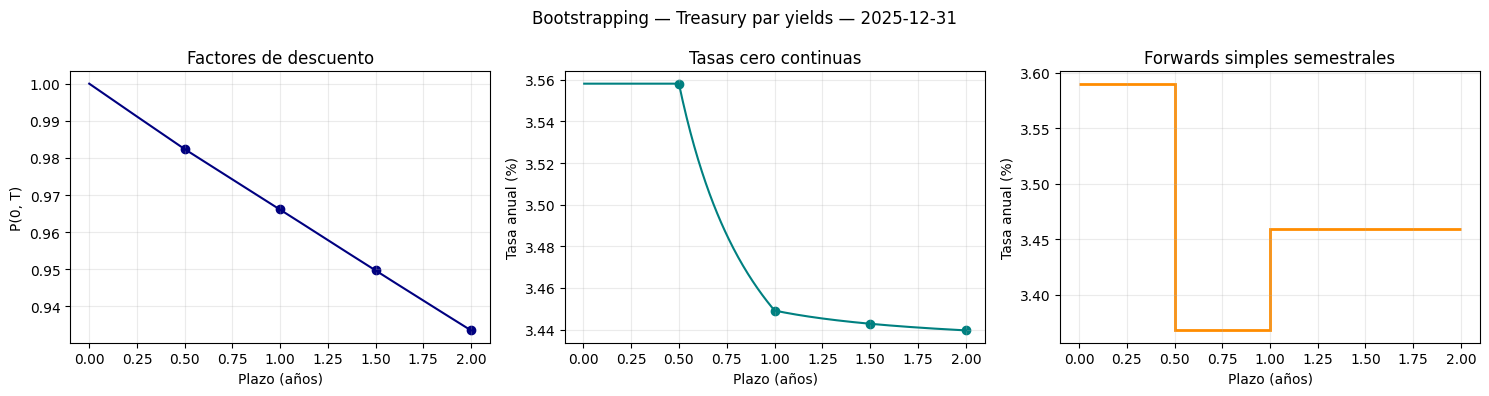

In [2]:
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy.optimize import brentq


# ------------------------------------------------------------
# 1. Descargar cotizaciones reales de una fuente oficial
# ------------------------------------------------------------

fecha_corte = pd.Timestamp("2025-12-31")

url = (
    "https://home.treasury.gov/resource-center/"
    "data-chart-center/interest-rates/TextView"
)

respuesta = requests.get(
    url,
    params={
        "type": "daily_treasury_yield_curve",
        "field_tdr_date_value": str(fecha_corte.year),
    },
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=60,
)
respuesta.raise_for_status()

tablas = pd.read_html(StringIO(respuesta.text))
columnas_necesarias = {"Date", "6 Mo", "1 Yr", "2 Yr"}

tabla = next(
    (
        tabla.copy()
        for tabla in tablas
        if columnas_necesarias.issubset(tabla.columns)
    ),
    None,
)

if tabla is None:
    raise ValueError(
        "La página no contiene las columnas esperadas. "
        "Revisa si el Tesoro cambió el formato de la tabla."
    )

tabla["Date"] = pd.to_datetime(
    tabla["Date"],
    format="%m/%d/%Y",
    errors="coerce",
)

columnas_tasas = ["6 Mo", "1 Yr", "2 Yr"]

for columna in columnas_tasas:
    tabla[columna] = pd.to_numeric(tabla[columna], errors="coerce")

datos = (
    tabla.loc[tabla["Date"] <= fecha_corte]
    .dropna(subset=["Date"] + columnas_tasas)
    .sort_values("Date")
)

if datos.empty:
    raise ValueError("No hay cotizaciones completas para la fecha solicitada.")

# Si la fecha solicitada no tiene datos, usamos la última anterior.
observacion = datos.iloc[-1]
fecha_datos = observacion["Date"]

# La fuente publica porcentajes. Convertimos a decimales.
k_6m, k_1y, k_2y = (
    observacion[columnas_tasas].to_numpy(dtype=float) / 100
)

cotizaciones = pd.DataFrame({
    "Vencimiento": ["6 meses", "1 año", "2 años"],
    "Tasa par (%)": [100 * k_6m, 100 * k_1y, 100 * k_2y],
})

print(f"Fecha de los datos: {fecha_datos.date()}")
print(cotizaciones.to_string(index=False))


# ------------------------------------------------------------
# 2. Bootstrap del descuento a seis meses
#
# 1 = (1 + 0.5 * k_6m) * D_6m
# ------------------------------------------------------------

delta = 0.5

D_6m = 1 / (1 + delta * k_6m)


# ------------------------------------------------------------
# 3. Bootstrap del descuento a un año
#
# 1 = 0.5 * k_1y * D_6m + (1 + 0.5 * k_1y) * D_1y
# ------------------------------------------------------------

D_1y = (1 - delta * k_1y * D_6m) / (1 + delta * k_1y)

if D_6m <= 0 or D_1y <= 0:
    raise ValueError("Los primeros descuentos no son positivos.")


# ------------------------------------------------------------
# 4. Bootstrap a dos años con interpolación a 18 meses
#
# D_18m = sqrt(D_1y * D_2y)
#
# 1 = 0.5 * k_2y * (D_6m + D_1y + D_18m + D_2y) + D_2y
# ------------------------------------------------------------

def error_precio_dos_anios(descuento_dos_anios):
    descuento_18_meses = np.sqrt(D_1y * descuento_dos_anios)

    valor_cupones = delta * k_2y * (
        D_6m
        + D_1y
        + descuento_18_meses
        + descuento_dos_anios
    )

    return valor_cupones + descuento_dos_anios - 1


limite_inferior = 1e-12
limite_superior = 2.0

# Ampliamos el intervalo si hace falta para encontrar cambio de signo.
for intento in range(30):
    if (
        error_precio_dos_anios(limite_inferior)
        * error_precio_dos_anios(limite_superior)
        < 0
    ):
        break

    limite_superior *= 2
else:
    raise ValueError("No se pudo acotar una raíz positiva.")

D_2y = brentq(
    error_precio_dos_anios,
    limite_inferior,
    limite_superior,
    xtol=1e-14,
)

D_18m = np.sqrt(D_1y * D_2y)


# ------------------------------------------------------------
# 5. Tasas cero continuas y forwards simples semestrales
# ------------------------------------------------------------

plazos = np.array([0.5, 1.0, 1.5, 2.0])
descuentos = np.array([D_6m, D_1y, D_18m, D_2y])

# z(0, T) = -log(D_T) / T
tasas_cero = -np.log(descuentos) / plazos

# Añadimos D(0, 0) = 1.
descuentos_anteriores = np.r_[1.0, descuentos[:-1]]

# F(0; T_i, T_{i+1}) = (D_i / D_{i+1} - 1) / delta
forwards = (
    descuentos_anteriores / descuentos - 1
) / delta

resultados = pd.DataFrame({
    "Plazo (años)": plazos,
    "Descuento": descuentos,
    "Tasa cero continua (%)": 100 * tasas_cero,
    "Periodo forward": [
        "0 a 6 meses",
        "6 a 12 meses",
        "12 a 18 meses",
        "18 a 24 meses",
    ],
    "Forward simple (%)": 100 * forwards,
})

print("\nCurva construida")
print(resultados.to_string(index=False, float_format=lambda x: f"{x:.8f}"))


# ------------------------------------------------------------
# 6. Revaluar los tres bonos par de nominal 100
# ------------------------------------------------------------

precio_6m = 100 * (1 + delta * k_6m) * D_6m

precio_1y = 100 * (
    delta * k_1y * D_6m
    + (1 + delta * k_1y) * D_1y
)

precio_2y = 100 * (
    delta * k_2y * descuentos.sum()
    + D_2y
)

precios = np.array([precio_6m, precio_1y, precio_2y])

validacion = pd.DataFrame({
    "Bono par": ["6 meses", "1 año", "2 años"],
    "Precio objetivo": 100.0,
    "Precio reconstruido": precios,
    "Error": precios - 100,
})

print("\nValidación")
print(validacion.to_string(index=False, float_format=lambda x: f"{x:.12f}"))

if not np.allclose(precios, 100.0, atol=1e-8, rtol=0):
    raise ArithmeticError("La curva no reproduce los precios objetivo.")


# ------------------------------------------------------------
# 7. Gráficas con la misma interpolación usada al calibrar
# ------------------------------------------------------------

pilares_tiempo = np.array([0.0, 0.5, 1.0, 2.0])
pilares_descuento = np.array([1.0, D_6m, D_1y, D_2y])

malla = np.linspace(0.0, 2.0, 401)

log_descuentos_malla = np.interp(
    malla,
    pilares_tiempo,
    np.log(pilares_descuento),
)

descuentos_malla = np.exp(log_descuentos_malla)

# Excluimos T=0 para evitar dividir entre cero.
tasas_cero_malla = -log_descuentos_malla[1:] / malla[1:]

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

ejes[0].plot(malla, descuentos_malla, color="navy")
ejes[0].scatter(plazos, descuentos, color="navy")
ejes[0].set_title("Factores de descuento")
ejes[0].set_ylabel("P(0, T)")

ejes[1].plot(malla[1:], 100 * tasas_cero_malla, color="teal")
ejes[1].scatter(plazos, 100 * tasas_cero, color="teal")
ejes[1].set_title("Tasas cero continuas")
ejes[1].set_ylabel("Tasa anual (%)")

ejes[2].stairs(
    100 * forwards,
    edges=np.r_[0.0, plazos],
    baseline=None,
    color="darkorange",
    linewidth=2,
)
ejes[2].set_title("Forwards simples semestrales")
ejes[2].set_ylabel("Tasa anual (%)")

for eje in ejes:
    eje.set_xlabel("Plazo (años)")
    eje.grid(alpha=0.25)

fig.suptitle(f"Bootstrapping — Treasury par yields — {fecha_datos.date()}")
plt.tight_layout()
plt.show()